# Deep Learning Lab 2 - Part 2: Vision Transformer from scratch on MNIST
Master MBD - Deep Learning - FST Tanger, Université Abdelmalek Essaadi.

The ViT follows Dosovitskiy et al. (2020) and the standard recipe: split the image into patches, project to a token embedding, prepend a learnable [CLS] token, add positional embeddings, pass through a stack of pre-norm Transformer encoder blocks (multi-head self-attention written by hand + MLP with GELU), and classify on the final [CLS] representation.

In [1]:
import os, sys
from pathlib import Path
if Path.cwd().name == "notebooks":
    os.chdir(Path.cwd().parent)
sys.path.insert(0, str(Path.cwd()))

import json, torch, pandas as pd
from IPython.display import Image, display
%matplotlib inline

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch:", torch.__version__, "| device:", device,
      torch.cuda.get_device_name(0) if device.type == "cuda" else "(CPU used for this lab)")


PyTorch: 2.14.1+cpu | device: cpu (CPU used for this lab)


## 1. Patch embedding and attention (from scratch)
Patch size 7 on 28x28 → **16 patches**, each of size 7x7 flattened to 49 pixels and projected to `embed_dim = 64`. Sequence length = 16 + 1 ([CLS]) = 17. 4 attention heads of 16 dimensions. 4 Transformer blocks, MLP ratio 2, dropout 0.1. Attention is implemented manually with `Q,K,V` linear projections, scaled dot-product attention `softmax(QK^T/sqrt(d)) V` and output projection.

Training: AdamW (lr=3e-4), CrossEntropyLoss, 3 epochs on **20 000** training images (smaller than the full 60k to stay within CPU time), evaluated on the **full 10 000 test images**.

In [2]:
from src.models import ViT
from src.utils import count_parameters

vit = ViT(img_size=28, patch_size=7, in_channels=1, num_classes=10,
          dim=64, depth=4, n_heads=4, mlp_ratio=2.0, dropout=0.1)
print(count_parameters(vit))
x = torch.randn(2, 1, 28, 28)
with torch.no_grad():
    tokens = vit.patch_embed(x)
    print('patch tokens shape:', tuple(tokens.shape), '->', tokens.shape[1], 'patches of dim', tokens.shape[2])
    cls = vit.cls_token.expand(2, -1, -1)
    print('[CLS] + tokens =', tuple(torch.cat([cls, tokens], dim=1).shape))

{'params_total': 139018, 'params_trainable': 139018}
patch tokens shape: (2, 16, 64) -> 16 patches of dim 64
[CLS] + tokens = (2, 17, 64)


In [3]:
vit_res = json.load(open('results/vit.json'))
print('device used:', vit_res['device'])
display(pd.DataFrame(vit_res['history']).round(4))

device used: cpu


,epoch,train_acc,test_acc,train_loss
0,1,0.5780,0.7223,1.2741
1,2,0.7786,0.8104,0.7056
2,3,0.8386,0.8401,0.5113


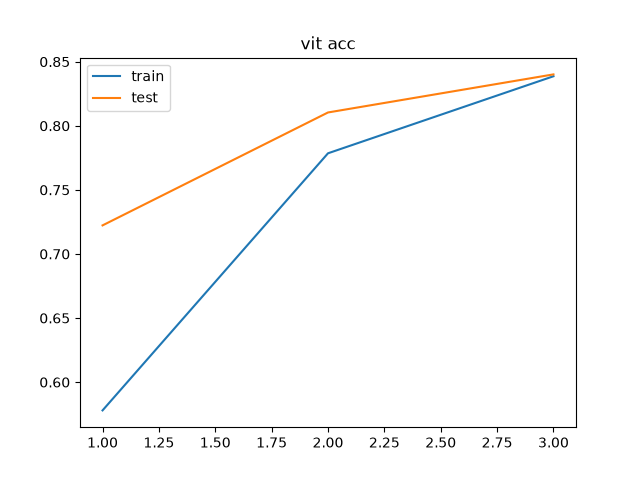

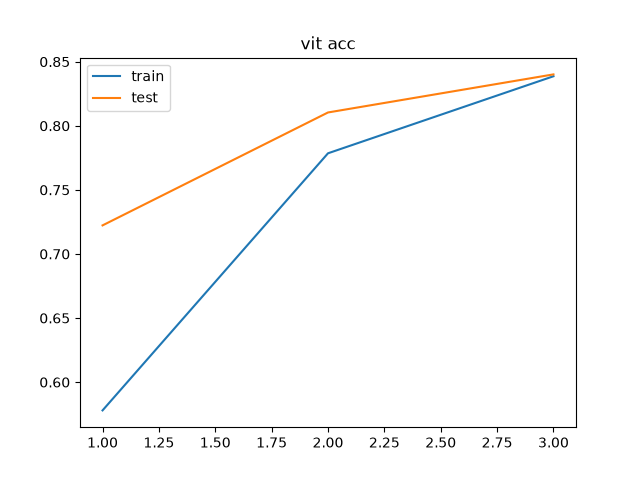

In [4]:
display(Image('figures/curves_vit_loss.png'))
display(Image('figures/curves_vit_acc.png'))

,Model,Accuracy,F1,Loss,TrainTime(s),Params,TrainImgs,TestImgs,Epochs,Device
0,CNN,0.9902,0.9901,0.0293,324.9498,421642,60000,10000,5,cpu
1,Faster R-CNN,0.7680,0.7198,NaN,98.2104,18976354,2000,1000,1,cpu
2,VGG16,0.7880,0.7881,NaN,270.5914,134301514,5000,2000,1,cpu
3,AlexNet,0.8665,0.8680,NaN,58.8627,57044810,5000,2000,1,cpu
4,ViT,0.8401,0.8399,NaN,39.1988,139018,20000,10000,3,cpu


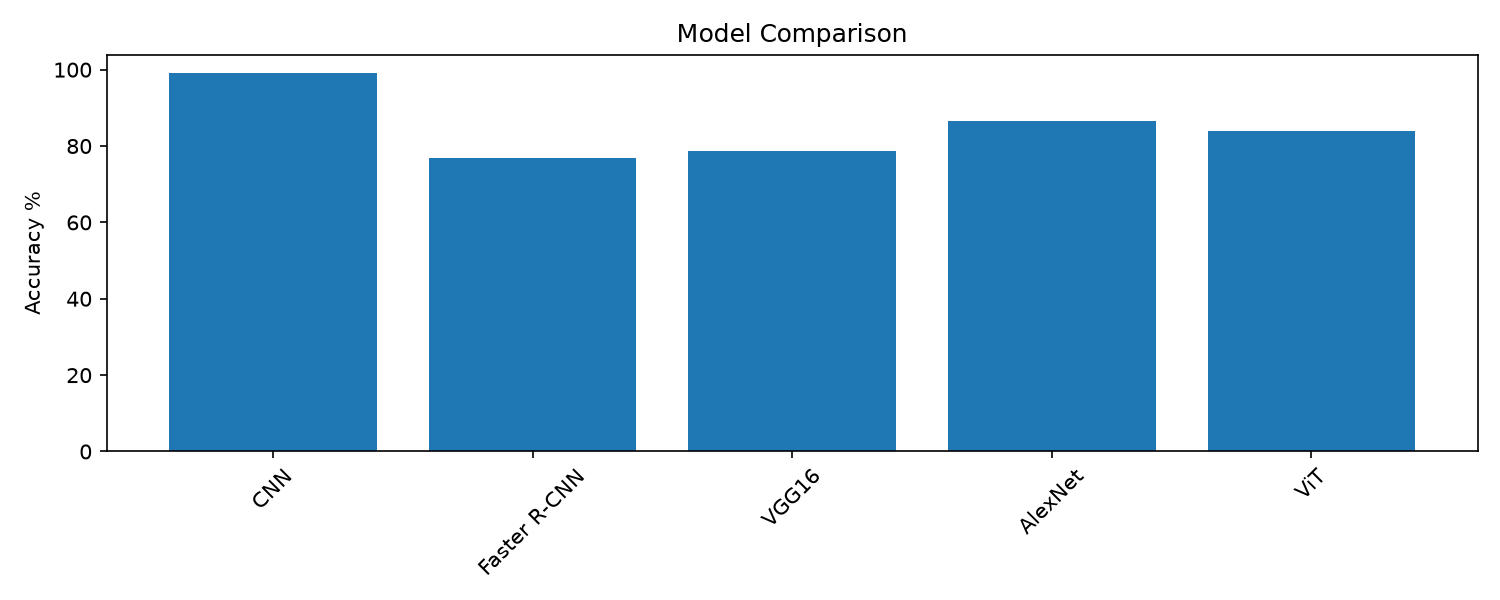

In [5]:
display(pd.read_csv('results/results_all.csv').round(4))
display(Image('figures/comparison.png'))

## 2. Comparison with Part 1 and interpretation
With 3 epochs on 20 000 images the ViT reaches **84.0% accuracy and 84.0% macro F1**, compared to **99.0%** for the CNN trained on all 60 000 images for 5 epochs. Several factors explain this:

- **Inductive bias.** Convolutions encode locality, translation equivariance and weight sharing from day one. A ViT has none of these: it must learn that adjacent patches form strokes and that spatial position matters purely from the data (via positional embeddings and self-attention).
- **Data efficiency.** ViTs are extremely data-hungry. As Dosovitskiy et al. showed, they match or exceed CNNs when pre-trained on huge datasets (ImageNet-21k, JFT) and then fine-tuned; on a small dataset like MNIST a CNN is much more sample-efficient.
- **Patch size.** Smaller patches give more tokens (more fine detail) but quadratic attention and longer training; larger patches are cheaper but lose resolution. Patch size 7 is a reasonable compromise here but still means the model sees only 16 local patches at first.
- **Training budget.** The curves show the ViT is still learning at epoch 3, so more epochs would help, but time is the constraint on CPU.

**Take-away:** the CNN is the right tool for MNIST. The ViT is correct and from-scratch as requested, but its advantage only appears with large-scale pretraining and enough compute/data.